# TP1 — Pipeline NLP classique : classification des locuteurs

**Notebook de travail et de référence — à comprendre, exécuter et personnaliser.**

Objectif : construire un pipeline NLP pour prédire le locuteur d'une réplique du corpus Tiny Shakespeare. Les scores et les observations sont calculés à l'exécution ; ils peuvent varier selon le corpus disponible et les versions des bibliothèques.

**Méthode :** le vocabulaire TF–IDF est ajusté uniquement sur les données d'entraînement afin d'éviter la fuite de données.

## 0. Imports et paramètres

In [21]:
import re
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 100)

## 1. Charger et observer le corpus

In [22]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
with urllib.request.urlopen(URL, timeout=30) as response:
    texte = response.read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print(texte[:1200])

1,115,394 caractères
40,000 lignes
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for 

**À observer :** le corpus est du texte brut. Les noms de personnages apparaissent souvent en majuscules, suivis de deux-points. Cette structure peut servir à créer automatiquement une étiquette de locuteur, mais le parsing reste imparfait : certains passages ne correspondent pas à ce format.

## 2. Extraire les répliques

In [23]:
def parser_repliques(txt: str) -> pd.DataFrame:
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.splitlines()
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0].strip())
        if entete and len(parties) > 1:
            replique = " ".join(p.strip() for p in parties[1:]).strip()
            if replique:
                lignes.append({
                    "locuteur": entete.group(1).strip(),
                    "replique": replique
                })
    return pd.DataFrame(lignes)

df = parser_repliques(texte)
df["n_mots"] = df["replique"].str.split().str.len()

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique():,} locuteurs distincts")
display(df.head())

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique,n_mots
0,First Citizen,"Before we proceed any further, hear me speak.",8
1,All,"Speak, speak.",2
2,First Citizen,You are all resolved rather to die than to famish?,10
3,All,Resolved. resolved.,2
4,First Citizen,"First, you know Caius Marcius is chief enemy to the people.",11


## 3. Explorer la distribution des classes

,nombre de répliques
locuteur,
GLOUCESTER,211
DUKE VINCENTIO,189
MENENIUS,161
ROMEO,160
PETRUCHIO,155
CORIOLANUS,148
KING RICHARD III,137
ISABELLA,127
LEONTES,124


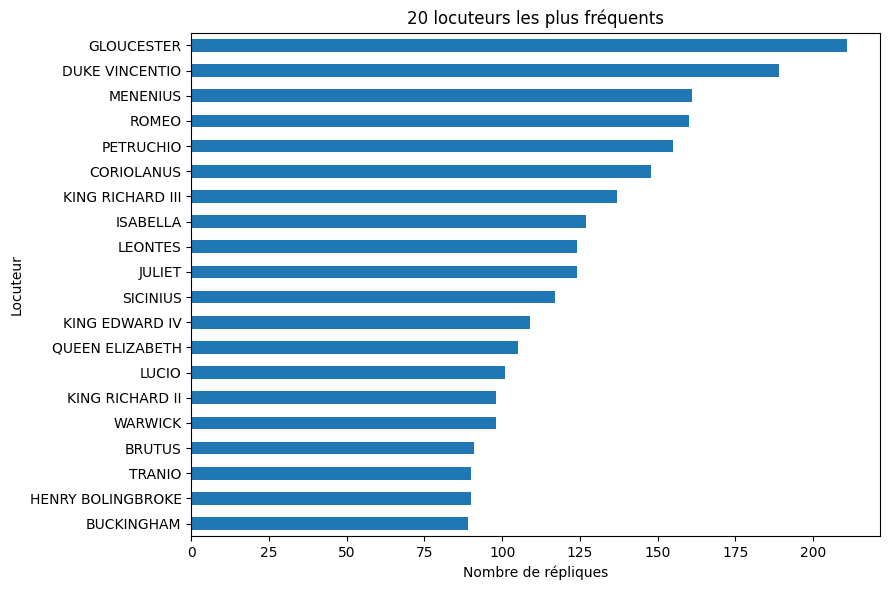

Longueur médiane (mots) : 14.0
Longueur moyenne (mots) : 27.18


In [24]:
top20 = df["locuteur"].value_counts().head(20)
display(top20.rename("nombre de répliques").to_frame())

ax = top20.sort_values().plot(kind="barh", figsize=(9, 6))
ax.set_title("20 locuteurs les plus fréquents")
ax.set_xlabel("Nombre de répliques")
ax.set_ylabel("Locuteur")
plt.tight_layout()
plt.show()

print("Longueur médiane (mots) :", df["n_mots"].median())
print("Longueur moyenne (mots) :", round(df["n_mots"].mean(), 2))

**Interprétation à vérifier après exécution :**
- Si les barres ont des tailles différentes, les classes ne sont pas équilibrées.
- Conserver beaucoup de locuteurs crée une tâche plus difficile et peut laisser très peu d'exemples pour certaines classes.
- Les répliques très courtes donnent peu d'indices lexicaux ; les filtrer peut aider, mais retire aussi des données.

## 4. Définir le jeu de données

In [25]:
N = 5
SEUIL_LONGUEUR = 5

top_speakers = df["locuteur"].value_counts().head(N).index.tolist()
donnees = df[
    df["locuteur"].isin(top_speakers) &
    (df["n_mots"] >= SEUIL_LONGUEUR)
][["replique", "locuteur"]].reset_index(drop=True)

print("Locuteurs retenus :", top_speakers)
display(donnees["locuteur"].value_counts().rename("exemples").to_frame())
print(f"Total après filtrage : {len(donnees)} répliques")

Locuteurs retenus : ['GLOUCESTER', 'DUKE VINCENTIO', 'MENENIUS', 'ROMEO', 'PETRUCHIO']


,exemples
locuteur,
GLOUCESTER,196
DUKE VINCENTIO,165
ROMEO,141
PETRUCHIO,133
MENENIUS,126


Total après filtrage : 761 répliques


**Pourquoi ces choix ?** Le notebook conserve les cinq locuteurs les plus fréquents et retire les répliques de moins de cinq mots. Cela réduit la difficulté et élimine une partie des textes trop courts pour fournir un signal lexical. Il faut toutefois vérifier les effectifs obtenus : les classes peuvent rester déséquilibrées.

## 5. Séparer train et test avant la vectorisation

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    donnees["replique"],
    donnees["locuteur"],
    test_size=0.20,
    stratify=donnees["locuteur"],
    random_state=RANDOM_STATE
)

print(f"Train : {len(X_train)} exemples")
print(f"Test  : {len(X_test)} exemples")
display(pd.DataFrame({
    "train": y_train.value_counts(),
    "test": y_test.value_counts()
}).fillna(0).astype(int))

Train : 608 exemples
Test  : 153 exemples


,train,test
locuteur,,
GLOUCESTER,156,40
DUKE VINCENTIO,132,33
ROMEO,113,28
PETRUCHIO,106,27
MENENIUS,101,25


La stratification conserve approximativement les proportions des locuteurs dans les deux ensembles. Le test est gardé à part jusqu'à l'évaluation finale.

## 6. Vectorisation TF–IDF

In [27]:
vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.90,
    stop_words=None,
    sublinear_tf=True
)

Xtr = vectoriseur.fit_transform(X_train)
Xte = vectoriseur.transform(X_test)

print("Taille du vocabulaire :", len(vectoriseur.vocabulary_))
print("Matrice train :", Xtr.shape)
print("Matrice test :", Xte.shape)
print(f"Proportion de valeurs non nulles : {Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.4%}")
print(f"Proportion de zéros : {1 - Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.4%}")

Taille du vocabulaire : 3464
Matrice train : (608, 3464)
Matrice test : (153, 3464)
Proportion de valeurs non nulles : 0.9716%
Proportion de zéros : 99.0284%


**Choix des paramètres :**
- `lowercase=True` regroupe les mots écrits avec des casses différentes.
- `ngram_range=(1, 2)` utilise les unigrammes et les bigrammes.
- `min_df=2` ignore les termes vus dans un seul document d'entraînement.
- `max_df=0.90` ignore les termes présents dans plus de 90 % des documents.
- `sublinear_tf=True` réduit l'effet des répétitions très fréquentes d'un terme.

La matrice est creuse : chaque réplique n'utilise qu'une petite partie du vocabulaire global. La conserver en format sparse économise de la mémoire.

In [28]:
idf_scores = pd.Series(
    vectoriseur.idf_,
    index=vectoriseur.get_feature_names_out()
)
print("15 termes avec IDF le plus élevé")
display(idf_scores.sort_values(ascending=False).head(15).to_frame("IDF"))
print("15 termes avec IDF le plus faible")
display(idf_scores.sort_values(ascending=True).head(15).to_frame("IDF"))

15 termes avec IDF le plus élevé


,IDF
able,6.313206
he may,6.313206
my way,6.313206
myself am,6.313206
myself and,6.313206
naked,6.313206
name and,6.313206
name is,6.313206
name of,6.313206
natural,6.313206


15 termes avec IDF le plus faible


,IDF
and,1.718086
the,1.741937
to,1.817107
you,1.982473
of,2.088808
that,2.175376
is,2.247032
in,2.293824
not,2.324222
my,2.355572


Un IDF élevé signale un terme rare dans les documents d'entraînement ; un IDF faible signale un terme répandu. Un terme rare n'est pas automatiquement utile : il peut être informatif, mais aussi être un artefact ou une faute de transcription.

## 7. Baselines

In [29]:
baseline_predictions = {}
for strategy in ["most_frequent", "stratified"]:
    model = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE)
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    baseline_predictions[strategy] = pred
    print(
        f"{strategy:>14} | accuracy={accuracy_score(y_test, pred):.3f} "
        f"| F1 macro={f1_score(y_test, pred, average='macro', zero_division=0):.3f}"
    )

 most_frequent | accuracy=0.261 | F1 macro=0.083
    stratified | accuracy=0.196 | F1 macro=0.189


La baseline `most_frequent` prédit toujours la classe majoritaire. La stratégie `stratified` tire des prédictions en respectant les proportions des classes. Un modèle utile doit dépasser ces références, notamment en F1 macro.

## 8. Entraîner et comparer plusieurs modèles

In [30]:
modeles = {
    "Naive Bayes": MultinomialNB(),
    "Régression logistique": LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "LinearSVC": LinearSVC(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
}

resultats = {}
modeles_entraines = {}

for nom, modele in modeles.items():
    modele.fit(Xtr, y_train)
    modeles_entraines[nom] = modele
    resultats[nom] = modele.predict(Xte)

lignes = []
for nom, pred in resultats.items():
    lignes.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_test, pred),
        "précision macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "rappel macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1 pondéré": f1_score(y_test, pred, average="weighted", zero_division=0),
    })

comparaison = pd.DataFrame(lignes).set_index("modèle").sort_values("F1 macro", ascending=False)
display(comparaison.round(3))

,accuracy,précision macro,rappel macro,F1 macro,F1 pondéré
modèle,,,,,
Régression logistique,0.667,0.671,0.669,0.668,0.667
LinearSVC,0.647,0.652,0.649,0.649,0.647
Naive Bayes,0.562,0.767,0.521,0.535,0.544


In [31]:
for nom, pred in resultats.items():
    print(f"\n--- {nom} ---")
    print(classification_report(y_test, pred, zero_division=0))


--- Naive Bayes ---
                precision    recall  f1-score   support

DUKE VINCENTIO       0.60      0.76      0.67        33
    GLOUCESTER       0.42      0.88      0.57        40
      MENENIUS       1.00      0.28      0.44        25
     PETRUCHIO       1.00      0.37      0.54        27
         ROMEO       0.82      0.32      0.46        28

      accuracy                           0.56       153
     macro avg       0.77      0.52      0.54       153
  weighted avg       0.73      0.56      0.54       153


--- Régression logistique ---
                precision    recall  f1-score   support

DUKE VINCENTIO       0.69      0.67      0.68        33
    GLOUCESTER       0.68      0.65      0.67        40
      MENENIUS       0.67      0.72      0.69        25
     PETRUCHIO       0.74      0.63      0.68        27
         ROMEO       0.58      0.68      0.62        28

      accuracy                           0.67       153
     macro avg       0.67      0.67      0.67  

**Comment lire les scores :** l'accuracy mesure la proportion totale de prédictions correctes. Le F1 macro calcule le F1 de chaque classe puis en fait la moyenne non pondérée ; il traite donc chaque locuteur à égalité. Le F1 pondéré tient compte du nombre d'exemples de chaque classe. Utilisez les valeurs affichées ci-dessus pour identifier le modèle le plus performant, plutôt que de recopier des scores calculés sur un autre lancement.

## 9. Matrice de confusion et analyse des erreurs

Modèle retenu selon le F1 macro : Régression logistique


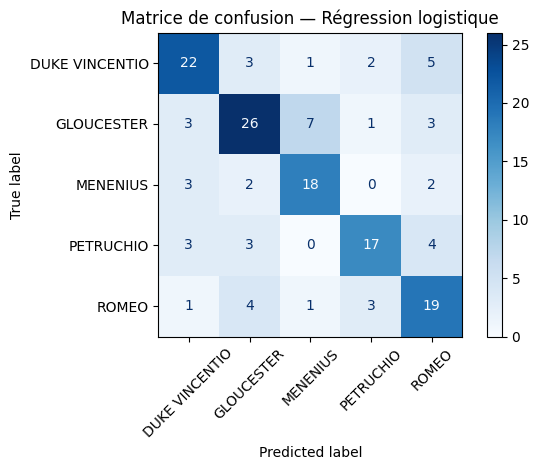

In [32]:
meilleur_modele = comparaison.index[0]
meilleures_predictions = resultats[meilleur_modele]

print("Modèle retenu selon le F1 macro :", meilleur_modele)
ConfusionMatrixDisplay.from_predictions(
    y_test, meilleures_predictions, xticks_rotation=45, cmap="Blues"
)
plt.title(f"Matrice de confusion — {meilleur_modele}")
plt.tight_layout()
plt.show()

In [33]:
mask_erreurs = meilleures_predictions != y_test.to_numpy()
df_erreurs = pd.DataFrame({
    "texte": X_test.to_numpy()[mask_erreurs],
    "vrai": y_test.to_numpy()[mask_erreurs],
    "prédit": meilleures_predictions[mask_erreurs],
})

print("Nombre d'erreurs :", len(df_erreurs))
if not df_erreurs.empty:
    paires = Counter(zip(df_erreurs["vrai"], df_erreurs["prédit"]))
    print("Paires vrai → prédit les plus fréquentes :")
    display(pd.DataFrame(
        [{"locuteur réel": a, "prédiction": b, "nombre": n}
         for (a, b), n in paires.most_common(10)]
    ))
    display(df_erreurs.sample(min(5, len(df_erreurs)), random_state=RANDOM_STATE))
else:
    print("Aucune erreur sur cet ensemble de test.")

Nombre d'erreurs : 51
Paires vrai → prédit les plus fréquentes :


,locuteur réel,prédiction,nombre
0,GLOUCESTER,MENENIUS,7
1,DUKE VINCENTIO,ROMEO,5
2,PETRUCHIO,ROMEO,4
3,ROMEO,GLOUCESTER,4
4,ROMEO,PETRUCHIO,3
5,PETRUCHIO,GLOUCESTER,3
6,GLOUCESTER,ROMEO,3
7,DUKE VINCENTIO,GLOUCESTER,3
8,MENENIUS,DUKE VINCENTIO,3
9,GLOUCESTER,DUKE VINCENTIO,3


,texte,vrai,prédit
43,"Now, my Lord Hastings and Sir William Stanley, Leave off to wonder why I drew you hither, Into t...",GLOUCESTER,DUKE VINCENTIO
40,"What then? 'Fore me, this fellow speaks! What then? what then?",MENENIUS,ROMEO
46,Let me stand here till thou remember it.,ROMEO,PETRUCHIO
12,"O, pardon me, Signior Gremio; I would fain be doing.",PETRUCHIO,GLOUCESTER
24,"O monstrous arrogance! Thou liest, thou thread, thou thimble, Thou yard, three-quarters, half-ya...",PETRUCHIO,ROMEO


**Analyse à rédiger à partir des sorties :**
1. Repérez la paire de locuteurs la plus souvent confondue.
2. Examinez les répliques correspondantes : sont-elles courtes, génériques, ou contiennent-elles des mots partagés ?
3. La matrice de confusion montre-t-elle une classe avec un rappel particulièrement faible ?
4. Proposez une explication fondée sur les exemples observés. Ne concluez pas que deux personnages viennent de la même pièce sans vérifier cette information dans le corpus.

## 10. Termes les plus associés aux classes

In [34]:
modele_logreg = modeles_entraines["Régression logistique"]
n_termes = 10
termes = vectoriseur.get_feature_names_out()

for i, classe in enumerate(modele_logreg.classes_):
    indices = np.argsort(modele_logreg.coef_[i])[-n_termes:][::-1]
    print(f"\n{classe} :")
    print(", ".join(termes[indices]))


DUKE VINCENTIO :
you, angelo, him, duke, provost, your, claudio, the duke, to, sir

GLOUCESTER :
king, clarence, lord, edward, my lord, cousin, god, warwick, the king, brother

MENENIUS :
he, you, marcius, like, rome, you have, tribunes, pray, general, the

PETRUCHIO :
kate, hortensio, come, and, sir, her, why, not, me, she

ROMEO :
love, thy, thou, mercutio, goose, night, what shall, dream, wilt, light


Ces termes ont des poids positifs élevés pour la classe considérée dans le modèle linéaire. Ils ne prouvent pas à eux seuls une relation sémantique : le modèle peut exploiter des noms, des expressions propres à un personnage ou des particularités du corpus.

## 11. Approfondissements facultatifs

### 11.1 Validation croisée sur le train

In [35]:
scores_cv = cross_val_score(
    LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE),
    Xtr, y_train, cv=5, scoring="f1_macro"
)
print("F1 macro par fold :", np.round(scores_cv, 3))
print(f"Moyenne ± écart-type : {scores_cv.mean():.3f} ± {scores_cv.std():.3f}")

F1 macro par fold : [0.638 0.613 0.581 0.546 0.6  ]
Moyenne ± écart-type : 0.596 ± 0.031


La dispersion des scores donne une indication de la sensibilité au découpage. La validation croisée est effectuée sur le train ; le test reste réservé à l'évaluation finale.

### 11.2 Comparer Bag of Words et TF–IDF

In [36]:
bow = CountVectorizer(
    lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.90
)
Xtr_bow = bow.fit_transform(X_train)
Xte_bow = bow.transform(X_test)

modele_bow = LogisticRegression(
    max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
)
modele_bow.fit(Xtr_bow, y_train)
pred_bow = modele_bow.predict(Xte_bow)

print(f"BoW — F1 macro : {f1_score(y_test, pred_bow, average='macro'):.3f}")
print(f"TF–IDF — F1 macro : {f1_score(y_test, resultats['Régression logistique'], average='macro'):.3f}")

BoW — F1 macro : 0.586
TF–IDF — F1 macro : 0.668


### 11.3 Augmenter le nombre de locuteurs

In [37]:
N2 = min(10, df["locuteur"].nunique())
locuteurs_10 = df["locuteur"].value_counts().head(N2).index.tolist()
donnees_10 = df[
    df["locuteur"].isin(locuteurs_10) &
    (df["n_mots"] >= SEUIL_LONGUEUR)
][["replique", "locuteur"]].reset_index(drop=True)

X_train_10, X_test_10, y_train_10, y_test_10 = train_test_split(
    donnees_10["replique"], donnees_10["locuteur"],
    test_size=0.20, stratify=donnees_10["locuteur"],
    random_state=RANDOM_STATE
)

pipe_10 = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, ngram_range=(1, 2), min_df=2,
        max_df=0.90, sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
    )),
])
pipe_10.fit(X_train_10, y_train_10)
pred_10 = pipe_10.predict(X_test_10)

print(f"{N} locuteurs — F1 macro : {f1_score(y_test, resultats['Régression logistique'], average='macro'):.3f}")
print(f"{N2} locuteurs — F1 macro : {f1_score(y_test_10, pred_10, average='macro'):.3f}")

5 locuteurs — F1 macro : 0.668
10 locuteurs — F1 macro : 0.418


L'ajout de classes rend généralement la tâche plus difficile, mais la variation exacte doit être constatée à partir des scores calculés. La comparaison reste sensible aux effectifs et à la difficulté propre des nouvelles classes.

### 11.4 Examiner le surapprentissage

In [38]:
for C in [0.01, 0.1, 1, 10, 100]:
    clf = LogisticRegression(
        C=C, max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
    )
    clf.fit(Xtr, y_train)
    print(f"C={C:>5} | train accuracy={clf.score(Xtr, y_train):.3f} "
          f"| test accuracy={clf.score(Xte, y_test):.3f}")

C= 0.01 | train accuracy=0.929 | test accuracy=0.601
C=  0.1 | train accuracy=0.938 | test accuracy=0.614
C=    1 | train accuracy=0.985 | test accuracy=0.667
C=   10 | train accuracy=1.000 | test accuracy=0.660
C=  100 | train accuracy=1.000 | test accuracy=0.654


Si le score d'entraînement est nettement supérieur au score de test, cela peut indiquer du surapprentissage. Dans la régression logistique, augmenter `C` réduit la régularisation ; un `C` trop élevé peut donc améliorer le score train sans améliorer la généralisation.

### 11.5 Construire un pipeline scikit-learn

In [39]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, ngram_range=(1, 2), min_df=2,
        max_df=0.90, sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
    )),
])

pipeline.fit(X_train, y_train)
pred_pipeline = pipeline.predict(X_test)
print(f"Pipeline — accuracy : {accuracy_score(y_test, pred_pipeline):.3f}")
print(f"Pipeline — F1 macro : {f1_score(y_test, pred_pipeline, average='macro'):.3f}")

Pipeline — accuracy : 0.667
Pipeline — F1 macro : 0.668
